# Lead Priority Engine for University Living
**Goal:** University Living receives a continuous stream of leads, but its accommodation experts can't reach everyone quickly.
This notebook builds the analysis behind a lead-priority engine: it scores each lead **the moment it arrives** by how likely it is to book (sections 1–5),
then by how much it's worth (section 6), and routes it to the right owner and response deadline.

**Success metric:** not accuracy, but *"with the same team, how many more bookings do we capture?"*

**Data:** there is no public University Living lead data, so we use the closest real funnel: *Lead Scoring – X Education* (Kaggle):
9,240 Indian, education-driven leads with mixed digital and referral channels, a live-chat channel, a calling sales team and a real converted label.
Every field is mapped to its University Living equivalent (see `01_business_context.md`).

Sections:
1. Load and understand the data
2. **The leakage trap**: why most lead-scoring models on this dataset would fail in production
3. University Living funnel insights (channels, browsing behaviour)
4. Build the score (only information available at arrival)
5. Business result: bookings captured for the same sales effort
6. **From probability to priority:** chance now × value, time fade and the 5-call limit from real data, the 60-day test of new + ongoing leads
7. Routing: match the channel's cost to the lead's value
8. Continuous re-scoring
9. Stress tests: algorithms, form answers, ablations, scenarios
10. Limitations and next steps

In [1]:
import pandas as pd, numpy as np, json, warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, brier_score_loss
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREY, RED, GREEN = '#2a6fdb', '#9aa3ad', '#d64545', '#2e9e6a'

raw = pd.read_csv('data/Leads.csv')
df = raw.replace('Select', np.nan)   # 'Select' = the form's default dropdown value, i.e. not answered
print(df.shape, '| conversion rate:', round(df.Converted.mean(), 3))

(9240, 37) | conversion rate: 0.385


## 1. Map the data to University Living's funnel
We rename the X Education values into University Living terms, so every insight below is in their language.

In [2]:
origin_map = {'Landing Page Submission': 'Website enquiry form', 'API': 'App / platform lead',
              'Lead Add Form': 'Counsellor / partner submitted', 'Lead Import': 'Bulk import (fairs, uni lists)',
              'Quick Add Form': 'Counsellor / partner submitted'}
def map_source(s):
    if pd.isna(s): return 'Unknown'
    s = str(s).lower()
    if s in ('reference', 'welingak website'): return 'Counsellor / referral'
    if s == 'olark chat': return 'Website chat (SABIE-like)'
    if s in ('google', 'organic search', 'bing'): return 'Search (SEO)'
    if s == 'direct traffic': return 'Direct traffic'
    if s in ('facebook', 'referral sites', 'social media'): return 'Social / affiliate sites'
    return 'Other'

ul = pd.DataFrame({
    'channel_origin':   df['Lead Origin'].map(origin_map),
    'channel_source':   df['Lead Source'].map(map_source),
    'no_email':         (df['Do Not Email'] == 'Yes').astype(int),
    'no_call':          (df['Do Not Call'] == 'Yes').astype(int),
    'visits':           df['TotalVisits'],
    'minutes_browsing': df['Total Time Spent on Website'] / 60,
    'pages_per_visit':  df['Page Views Per Visit'],
    'profile_fields_filled': df[['What is your current occupation', 'Specialization', 'City']].notna().sum(axis=1),
    'booked':           df['Converted'],
})
ul.to_csv('data/ul_leads_clean.csv', index=False)
ul.head()

,channel_origin,channel_source,no_email,no_call,visits,minutes_browsing,pages_per_visit,profile_fields_filled,booked
0,App / platform lead,Website chat (SABIE-like),0,0,0.0,0.000000,0.0,1,0
1,App / platform lead,Search (SEO),0,0,5.0,11.233333,2.5,1,0
2,Website enquiry form,Direct traffic,0,0,2.0,25.533333,2.0,3,1
3,Website enquiry form,Direct traffic,0,0,1.0,5.083333,1.0,3,0
4,Website enquiry form,Search (SEO),0,0,2.0,23.800000,1.0,2,1


## 2. The leakage trap
Some columns are written **by the sales team after they contact the lead**. The data dictionary confirms it: `Lead Quality` is *"based on the data and intuition of the employee who has been assigned to the lead"*, and `Tags` is the *"current status of the lead"*.

A model that uses them is reading the outcome, not predicting it. And at the moment a lead arrives, those columns are empty.

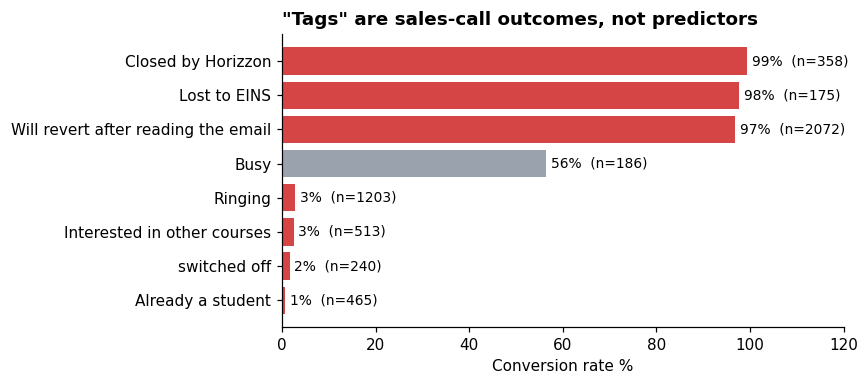

In [3]:
t = df.groupby('Tags').Converted.agg(['count', 'mean']).query('count > 150').sort_values('mean')
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(t.index, t['mean'] * 100, color=[RED if v > .9 or v < .05 else GREY for v in t['mean']])
for i, (n, v) in enumerate(zip(t['count'], t['mean'])): ax.text(v * 100 + 1, i, f'{v:.0%}  (n={n})', va='center', fontsize=9)
ax.set_xlim(0, 120); ax.set_xlabel('Conversion rate %')
ax.set_title('"Tags" are sales-call outcomes, not predictors', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/leakage_tags.png'); plt.show()

Note also **"Lost to EINS"** (lost to a competitor) shows ~98% *converted*: a contradiction that suggests labels were logged inconsistently. In production, label quality needs auditing too.

**Proof of the trap:** the same model trained with and without the post-contact columns.

In [4]:
NUM = ['visits', 'minutes_browsing', 'pages_per_visit']
def design(frame):
    X = frame.copy()
    for c in X.columns:
        if X[c].dtype == object: X[c] = X[c].fillna('Unknown')
        else: X[c] = X[c].fillna(X[c].median())
    X = pd.get_dummies(X).astype(float)
    for c in NUM:
        if c in X: X[c] = np.log1p(X[c])
    return X

y = ul['booked']
X_clean = design(ul.drop(columns='booked'))
leak_cols = ['Tags', 'Lead Quality', 'Last Activity', 'Last Notable Activity', 'Lead Profile']
X_leaky = pd.concat([X_clean, design(df[leak_cols])], axis=1)

idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.3, random_state=42, stratify=y)
def fit_eval(X):
    m = HistGradientBoostingClassifier(random_state=0).fit(X.iloc[idx_tr], y.iloc[idx_tr])
    return m, m.predict_proba(X.iloc[idx_te])[:, 1]
_, p_leaky = fit_eval(X_leaky)
model, p = fit_eval(X_clean)
y_te = y.iloc[idx_te].values
print(f'With post-contact columns : AUC {roc_auc_score(y_te, p_leaky):.3f}, accuracy {((p_leaky > .5) == y_te).mean():.1%}  <- looks great, unusable at arrival')
print(f'Arrival-time columns only : AUC {roc_auc_score(y_te, p):.3f}, accuracy {((p > .5) == y_te).mean():.1%}  <- honest, usable the moment a lead lands')

With post-contact columns : AUC 0.978, accuracy 93.8%  <- looks great, unusable at arrival
Arrival-time columns only : AUC 0.856, accuracy 79.2%  <- honest, usable the moment a lead lands


The ~94% model is what most public solutions report. It would collapse in production, because the score is needed **before** the sales call, and those columns are filled **after** it. From here on, we use only information available when the lead arrives.

## 3. University Living funnel insights
### 3a. Channel quality: volume vs. intent

,leads,booking_rate,share_of_leads,share_of_bookings
channel_source,,,,
Search (SEO),4033,39%,44%,44%
Direct traffic,2543,32%,28%,23%
Website chat (SABIE-like),1755,26%,19%,13%
Counsellor / referral,676,93%,7%,18%
Social / affiliate sites,182,25%,2%,1%
Unknown,36,81%,0%,1%
Other,15,47%,0%,0%


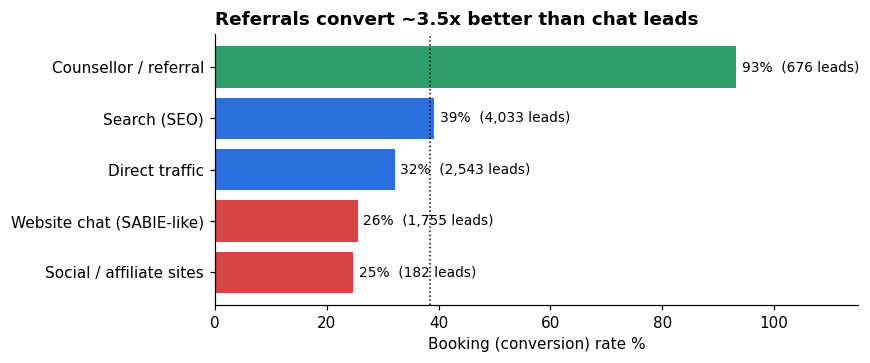

In [5]:
ch = ul.groupby('channel_source').booked.agg(leads='count', booking_rate='mean').sort_values('leads', ascending=False)
ch['share_of_leads'] = ch.leads / ch.leads.sum()
ch['share_of_bookings'] = ul.groupby('channel_source').booked.sum() / ul.booked.sum()
display(ch.style.format({'booking_rate': '{:.0%}', 'share_of_leads': '{:.0%}', 'share_of_bookings': '{:.0%}'}))

fig, ax = plt.subplots(figsize=(8, 3.4))
c2 = ch[ch.leads >= 100].sort_values('booking_rate')  # hide tiny groups
ax.barh(c2.index, c2.booking_rate * 100, color=[GREEN if v > .8 else (RED if v < .3 else BLUE) for v in c2.booking_rate])
for i, (r, n) in enumerate(zip(c2.booking_rate, c2.leads)): ax.text(r * 100 + 1, i, f'{r:.0%}  ({n:,} leads)', va='center', fontsize=9)
ax.axvline(ul.booked.mean() * 100, color='k', ls=':', lw=1); ax.set_xlim(0, 115); ax.set_xlabel('Booking (conversion) rate %')
ax.set_title('Referrals convert ~3.5x better than chat leads', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/channels.png'); plt.show()

**So what for University Living:** counsellor/referral leads are a small share of volume but convert above 90%. Chat (SABIE-like) produces lots of leads at a low rate.
→ Referral leads should go straight to a human. Chat leads need nurturing or qualification (e.g. by the AI voice agent) before an expert spends time on them.
→ Track **booking rate per counsellor/partner**, not just lead count. Partners who send volume without bookings cost expert time.

### 3b. Browsing depth: the "10-minute line" 

,count,mean
browse_band,,
0,2193,42%
0-2,1241,13%
2-5,1615,14%
5-10,1239,19%
10-15,560,61%
15-20,897,71%
20-30,1368,69%
30+,127,71%



Who are the 0-minute leads?
channel_origin
App / platform lead               0.73
Counsellor / partner submitted    0.25
Bulk import (fairs, uni lists)    0.01
Website enquiry form              0.00
Name: proportion, dtype: float64


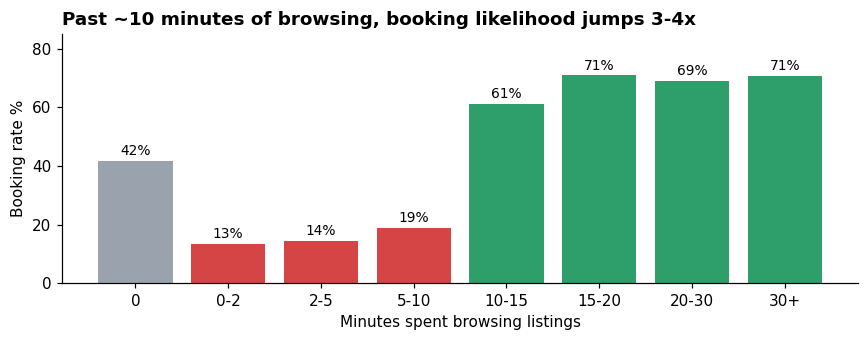

In [6]:
bins = [-0.01, 0, 2, 5, 10, 15, 20, 30, 1e9]
labels = ['0', '0-2', '2-5', '5-10', '10-15', '15-20', '20-30', '30+']
ul['browse_band'] = pd.cut(ul.minutes_browsing, bins, labels=labels)
bb = ul.groupby('browse_band', observed=True).booked.agg(['count', 'mean'])
display(bb.style.format({'mean': '{:.0%}'}))
print('\nWho are the 0-minute leads?'); print(ul[ul.minutes_browsing == 0].channel_origin.value_counts(normalize=True).round(2))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(bb.index.astype(str), bb['mean'] * 100, color=[GREY] + [RED if v < .3 else GREEN for v in bb['mean'][1:]])
for i, v in enumerate(bb['mean']): ax.text(i, v * 100 + 2, f'{v:.0%}', ha='center', fontsize=9)
ax.set_xlabel('Minutes spent browsing listings'); ax.set_ylabel('Booking rate %'); ax.set_ylim(0, 85)
ax.set_title('Past ~10 minutes of browsing, booking likelihood jumps 3-4x', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/browsing.png'); plt.show()
ul = ul.drop(columns='browse_band')

**So what for University Living:**
- Leads browsing **10+ minutes** convert at 60-70%, versus under 20% for short sessions. This is a **real-time trigger**: when a student crosses the line, alert an expert or WhatsApp them while they're still on the site.
- **0-minute leads are not low intent.** They convert at ~42% because they never browsed the website: ~73% came in through the app / platform integration and ~25% were submitted by a counsellor. A naive "engagement score" would wrongly bury them. The model learns this from channel × behaviour together.

## 4. Build the score
Inputs, all available at arrival: channel (origin + source), contact consent, browsing depth, and how much of the enquiry form was filled.
We compared a simple, transparent model (logistic regression) with gradient boosting, and checked stability with 5-fold cross-validation.

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
for name, m in [('Logistic regression', LogisticRegression(max_iter=3000)),
                ('Gradient boosting  ', HistGradientBoostingClassifier(random_state=0))]:
    s = cross_val_score(m, X_clean, y, cv=cv, scoring='roc_auc')
    print(f'{name} AUC {s.mean():.3f} ± {s.std():.3f}')

Logistic regression AUC 0.842 ± 0.008


Gradient boosting   AUC 0.861 ± 0.004


Gradient boosting is consistently better and stable across folds, so it's the scoring model. **Calibration check:** the score is used as a probability (and later multiplied by booking value), so predicted 70% should mean ~70% actually book.

Brier score: 0.148


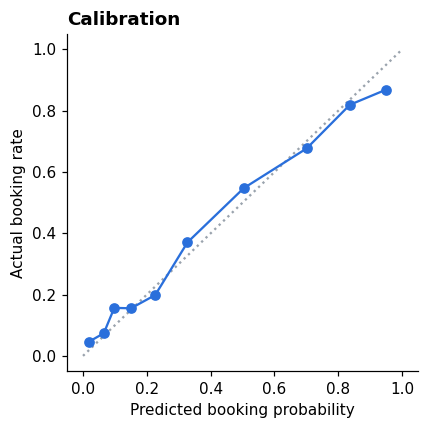

In [8]:
cal = pd.DataFrame({'pred': p, 'actual': y_te}).assign(decile=lambda d: pd.qcut(d.pred, 10, labels=False, duplicates='drop'))
cal = cal.groupby('decile').mean()
print('Brier score:', round(brier_score_loss(y_te, p), 3))
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], ':', color=GREY); ax.plot(cal.pred, cal.actual, 'o-', color=BLUE)
ax.set_xlabel('Predicted booking probability'); ax.set_ylabel('Actual booking rate'); ax.set_title('Calibration', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

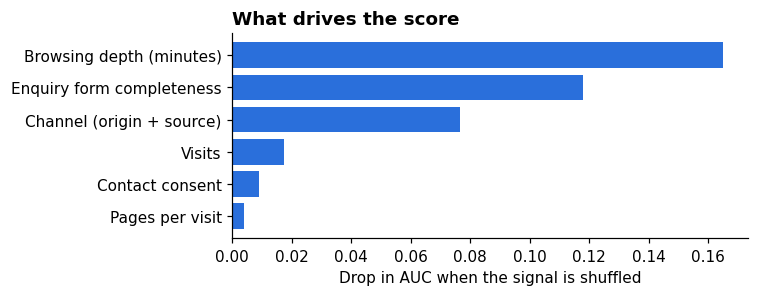

In [9]:
imp = permutation_importance(model, X_clean.iloc[idx_te], y_te, scoring='roc_auc', n_repeats=5, random_state=0)
groups = {'Channel (origin + source)': 'channel_', 'Browsing depth (minutes)': 'minutes_browsing', 'Visits': 'visits',
          'Pages per visit': 'pages_per_visit', 'Enquiry form completeness': 'profile_fields_filled', 'Contact consent': 'no_'}
gi = {g: sum(v for c, v in zip(X_clean.columns, imp.importances_mean) if c.startswith(pref)) for g, pref in groups.items()}
gi = pd.Series(gi).sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8)); ax.barh(gi.index, gi.values, color=BLUE)
ax.set_xlabel('Drop in AUC when the signal is shuffled'); ax.set_title('What drives the score', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/drivers.png'); plt.show()

## 5. Business result: more bookings for the same effort
The question sales leadership actually asks: *"If my team can only reach X% of leads quickly, what share of eventual bookings is in that X%?"*
- **No scoring** (first come, first served) captures X% of bookings with X% of leads.
- **Perfect foresight** is the ceiling.

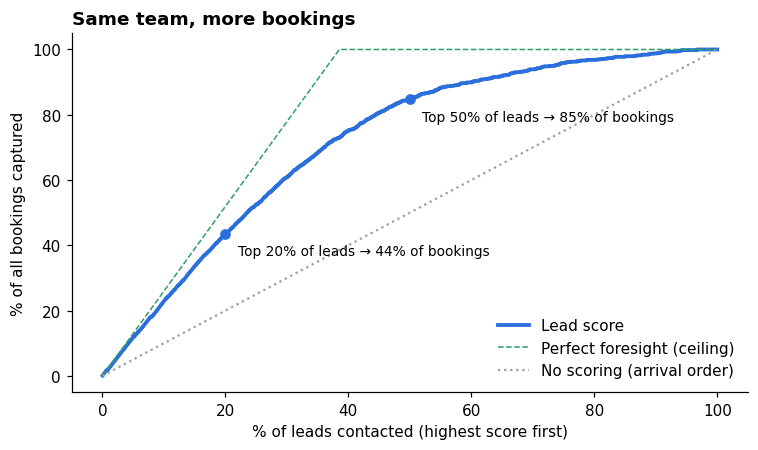

Top 20%: 44% of bookings vs 20% unscored (2.2x), 84% of the theoretical max (52%)
Top 50%: 85% of bookings


In [10]:
order = np.argsort(-p); hits = y_te[order]
frac = np.arange(1, len(hits) + 1) / len(hits); captured = np.cumsum(hits) / hits.sum()
perfect = np.minimum(frac * len(hits) / hits.sum(), 1)
def cap(x): return captured[int(x * len(hits)) - 1]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(frac * 100, captured * 100, color=BLUE, lw=2.5, label='Lead score')
ax.plot(frac * 100, perfect * 100, color=GREEN, ls='--', lw=1, label='Perfect foresight (ceiling)')
ax.plot([0, 100], [0, 100], color=GREY, ls=':', label='No scoring (arrival order)')
for x in (.2, .5):
    ax.scatter(x * 100, cap(x) * 100, color=BLUE, zorder=5)
    ax.annotate(f'Top {x:.0%} of leads → {cap(x):.0%} of bookings', (x * 100, cap(x) * 100), xytext=(8, -14), textcoords='offset points', fontsize=9)
ax.set_xlabel('% of leads contacted (highest score first)'); ax.set_ylabel('% of all bookings captured')
ax.set_title('Same team, more bookings', loc='left', fontweight='bold'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('charts/gains.png'); plt.show()
ceiling20 = perfect[int(.2 * len(hits)) - 1]
print(f'Top 20%: {cap(.2):.0%} of bookings vs 20% unscored ({cap(.2)/.2:.1f}x), {cap(.2)/ceiling20:.0%} of the theoretical max ({ceiling20:.0%})')
print(f'Top 50%: {cap(.5):.0%} of bookings')

## 6. From probability to priority
**Rank leads by what they're likely to earn, not just whether they'll book.**

Standard lead scoring stops at section 5: *who is likely to book?* At University Living that misses two things:
1. **Value.** Commission follows the rent, and every student enquires **on a specific property**, so the lead's value is known at arrival.
2. **Time.** A booking takes days to weeks, so every day the team chooses between **new leads and ongoing ones**.

```
Priority      = chance to book NOW × revenue value × visa grant rate
chance now    = chance at enquiry (section 5 model) × fade (days the lead has been open)
5-call limit  : after 5 unanswered calls a lead moves to nurture, until the student acts again
revenue value = rent commission + per-student extras (assumed ₹15,000)
```

Each part comes from real data. The datasets are **not merged** (they describe different people); each answers one question.
From here on the notebook uses the production code in `workflow/`.

In [11]:
import sys; sys.path.insert(0, 'workflow')
from engine import WEEKLY_RENT, COMMISSION_RATE, GBP_TO_INR, VISA_GRANT, inr, LeadPriorityEngine
W = json.load(open('workflow/console_data.json')); X = json.load(open('workflow/experiments.json'))
PIPE = json.load(open('workflow/pipeline.json')); SH = json.load(open('workflow/config.json'))['shapes']
rent = pd.Series(WEEKLY_RENT).unstack()
print(f'Weekly rent in rupees (published 2025/26 surveys in GBP, converted at ₹{GBP_TO_INR} per £):')
display(rent.apply(lambda col: col.map(inr)))
print(f'Commission value ranges from {inr(min(WEEKLY_RENT.values()) * 44 * COMMISSION_RATE)} '
      f'to {inr(max(WEEKLY_RENT.values()) * 51 * COMMISSION_RATE)} per booking at a {COMMISSION_RATE:.0%} rate: a 2.6x spread.')
print(f'Visa grant rate (Home Office, Indian nationals, 2025): {VISA_GRANT:.0%}')

Weekly rent in rupees (published 2025/26 surveys in GBP, converted at ₹127 per £):


,En-suite,Studio
Birmingham,"₹20,955","₹31,115"
London,"₹32,893","₹43,307"
Manchester,"₹22,225","₹33,020"
Other UK city,"₹19,431","₹28,956"


Commission value ranges from ₹85,496 to ₹2,20,866 per booking at a 10% rate: a 2.6x spread.
Visa grant rate (Home Office, Indian nationals, 2025): 96%


### 6a. Two real-data curves for ongoing leads
- **When to stop calling (UCI Bank Marketing, 41,188 customers called repeatedly):** the chance that the *k*-th call converts, given no "yes" before it.
  Computed this way (not "conversion by number of calls") to avoid survivor bias: people who said yes early stopped being called.
  By the 5th call it is under half the 1st and keeps falling, which sets the **5-call limit**. The bank's *call duration* column is only known after a call, so it is never used.
- **Fade (Olist marketing funnel, 8,000 leads):** days from first contact to a closed deal, using only leads with at least 180 days to close.

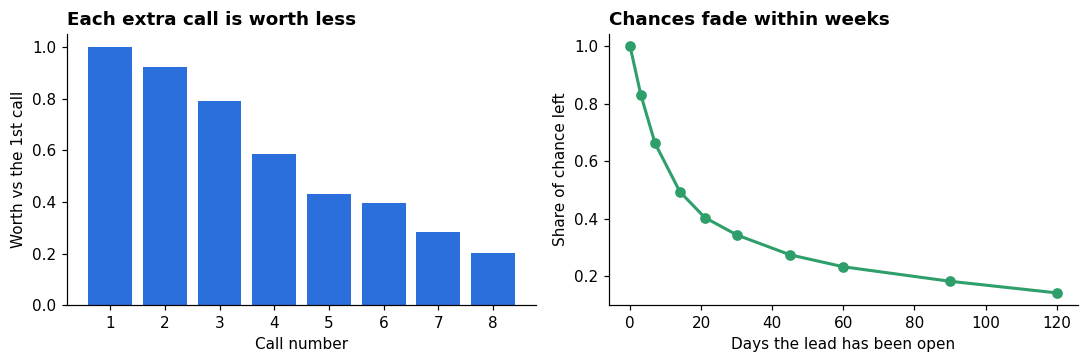

k-th call vs the 1st (sets the 5-call limit): [1.0, 0.921, 0.7922, 0.584, 0.4312, 0.3968, 0.2828, 0.203]
Fade at days [0, 3, 7, 14, 21, 30, 45, 60] -> [1.0, 0.8321, 0.6629, 0.4937, 0.404, 0.3434, 0.274, 0.2323]


In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.bar(range(1, 9), SH['call_mult'][:8], color=BLUE); a1.set_xlabel('Call number'); a1.set_ylabel('Worth vs the 1st call')
a1.set_title('Each extra call is worth less', loc='left', fontweight='bold')
a2.plot(SH['fade_days'][:10], SH['fade'][:10], color=GREEN, marker='o', lw=2); a2.set_xlabel('Days the lead has been open')
a2.set_ylabel('Share of chance left'); a2.set_title('Chances fade within weeks', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/fatigue_fade.png'); plt.show()
print('k-th call vs the 1st (sets the 5-call limit):', SH['call_mult'][:8]); print('Fade at days', SH['fade_days'][:8], '->', SH['fade'][:8])

### 6b. One real day: where the two rankings disagree
Today's queue: 92 new leads plus 40 ongoing follow-ups (their call history comes from the 60-day test). Same 25 expert calls.
Some ongoing leads have already booked elsewhere; the team can't see that, but the replay can.

In [13]:
eng = LeadPriorityEngine()
new = pd.DataFrame(W['inbox']).assign(arrival=lambda d: range(len(d)))
ongoing = pd.DataFrame(PIPE['ongoing']).assign(arrival=lambda d: -1000 - d.days_open)
day = eng.score(pd.concat([new, ongoing], ignore_index=True).drop(columns='p_book'))
day['moved_on'] = day.moved_on.eq(True); day['real'] = (day.booked == 1) & ~day.moved_on; day['first'] = -day.arrival
pick = lambda key: day.sort_values([key, 'first'], ascending=False).head(25)
std, pri = pick('p_book'), pick('priority')
show = ['lead_id', 'stage', 'attempts', 'days_open', 'city', 'room', 'p_book', 'p_now', 'value', 'priority']
print('Called by standard scoring only:'); display(std[~std.lead_id.isin(pri.lead_id)][show].round(2).head(4))
print('Called by priority only:'); display(pri[~pri.lead_id.isin(std.lead_id)][show].round(2).head(4))
for name, t in [('Standard', std), ('Priority', pri)]:
    print(f'{name:9} real outcome: {int(t.real.sum())} real bookers reached, {inr((t.real * t.value * VISA_GRANT).sum())} after visa risk')

Called by standard scoring only:


,lead_id,stage,attempts,days_open,city,room,p_book,p_now,value,priority
122,580713,Follow-up,2.0,17.0,Other UK city,En-suite,1.00,0.45,898.41,391.16
92,643871,Follow-up,1.0,4.0,Birmingham,En-suite,0.97,0.77,959.61,705.85
94,613624,Follow-up,1.0,30.0,Manchester,En-suite,0.96,0.33,888.11,281.97
118,637163,Follow-up,1.0,15.0,Manchester,En-suite,0.96,0.46,1010.61,447.79


Called by priority only:


,lead_id,stage,attempts,days_open,city,room,p_book,p_now,value,priority
10,622285,New,0.0,0.0,London,Studio,0.76,0.76,1857.21,1357.54
61,613405,New,0.0,0.0,London,Studio,0.71,0.71,1857.21,1269.96
83,586629,New,0.0,0.0,London,Studio,0.74,0.74,1618.51,1150.68
44,621055,New,0.0,0.0,London,En-suite,0.82,0.82,1439.01,1130.49


Standard  real outcome: 20 real bookers reached, ₹26,51,651 after visa risk
Priority  real outcome: 20 real bookers reached, ₹33,03,581 after visa risk


### 6c. The 60-day test, and an idea that failed
2,772 held-out leads arrive at ~92 a day for 30 days; the test runs for 60. Each booker needs a number of calls drawn from the bank data and keeps
looking for a number of days drawn from the Olist data. Every rule gets the same calls, the same follow-up spacing (2 days) and the same 5-call limit,
so standard scoring is a realistic baseline, not a strawman.

Two ideas were tested and **dropped**:
- **Move-in urgency** on top of priority: lead volume exceeds capacity, so a lead pushed to "later" is rarely called at all.
- **Precise call fatigue** (lowering each lead's chance per unanswered call with the bank curve): it won when students behaved like the bank's
  customers but lost if they needed one more call. The simple 5-call limit is robust (see section 9).

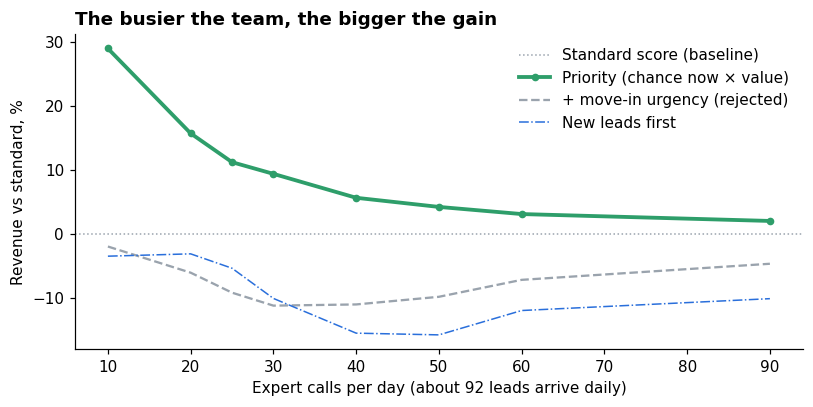

,10,20,25,30,40,50,60,90
arrival,-74.8,-73.4,-72.8,-70.4,-67.6,-63.3,-60.3,-46.5
new_first,-3.4,-3.1,-5.3,-10.1,-15.5,-15.7,-11.9,-10.1
standard,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
priority,29.0,15.7,11.2,9.4,5.7,4.2,3.1,2.1
with_urgency,-1.9,-6.0,-9.2,-11.2,-11.0,-9.8,-7.1,-4.6


Bookings at 25 calls/day: {'arrival': 105, 'new_first': 367, 'standard': 387, 'priority': 380, 'with_urgency': 326}
Where the gain comes from: {'standard': '+0.0%', 'value_only': '+7.7%', 'fade_only': '+7.2%', 'priority': '+11.2%'}


In [14]:
caps, cur = PIPE['caps'], PIPE['curve']
rel = pd.DataFrame({r: [v[0] / s[0] - 1 for v, s in zip(cur[r], cur['standard'])] for r in cur}, index=caps) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.axhline(0, color=GREY, ls=':', lw=1, label='Standard score (baseline)')
ax.plot(rel.index, rel.priority, color=GREEN, lw=2.5, marker='o', ms=4, label='Priority (chance now × value)')
# all rules stop after 5 unanswered calls
ax.plot(rel.index, rel.with_urgency, color=GREY, lw=1.5, ls='--', label='+ move-in urgency (rejected)')
ax.plot(rel.index, rel.new_first, color=BLUE, lw=1, ls='-.', label='New leads first')
ax.set_xlabel('Expert calls per day (about 92 leads arrive daily)'); ax.set_ylabel('Revenue vs standard, %')
ax.set_title('The busier the team, the bigger the gain', loc='left', fontweight='bold'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('charts/simulation.png'); plt.show()
display(rel.round(1).T)
k = caps.index(25); print('Bookings at 25 calls/day:', {r: round(cur[r][k][1]) for r in cur})
print('Where the gain comes from:', {r: f"{v[0] / PIPE['parts']['standard'][0] - 1:+.1%}" for r, v in PIPE['parts'].items()})

**So what for University Living:** see the table: priority earns more revenue than standard scoring at every team size, with more
bookings, because it spends calls on fresh, valuable leads instead of stale ones. The gain is largest when the team is most stretched,
as in **peak season (July–September)**.

## 7. Routing: match the channel's cost to the lead's value
| | Lower value | Higher value |
|---|---|---|
| **Likely to book now** | Close cheaply: AI voice agent with a booking link | Protect: senior expert within 5 min |
| **Less likely now** | Nurture: WhatsApp / email, re-scored on activity | Persuade: expert consultative call |

A lead that stays open slides from Protect towards Nurture as its chance now fades; after 5 unanswered calls it moves to nurture.
The 5-minute deadline follows the MIT/InsideSales finding that leads contacted within 5 minutes are ~21x more likely to qualify than at 30.
Consent is a rule, not a feature: a student who opted out of calls is never phoned.

## 8. Continuous re-scoring
Leads keep changing after they arrive. The engine re-scores a lead on every new action.

In [15]:
cold = day[(day.p_now < 0.25) & (day.minutes_browsing > 0)]
rows = []
for _, l in cold.head(4).iterrows():
    r = eng.rescore(l.to_dict(), extra_minutes=15, extra_visits=1)
    rows.append({'lead_id': l.lead_id, 'stage': l.stage, 'chance now before': f"{r['p_before']:.0%}", 'after': f"{r['p_after']:.0%}",
                 'play before': r['play_before'], 'play after': r['play_after'], 'respond within': r['sla_after']})
print('A cold lead returns and browses 15 more minutes:'); display(pd.DataFrame(rows))

A cold lead returns and browses 15 more minutes:


,lead_id,stage,chance now before,after,play before,play after,respond within
0,584936,New,2%,25%,Nurture,Nurture,24 hours
1,633443,New,6%,83%,Nurture,Close cheaply,15 min
2,644288,New,17%,86%,Persuade,Protect,5 min
3,644117,New,2%,44%,Nurture,Nurture,24 hours


## 9. Stress tests

In [16]:
display(pd.DataFrame(X['models']).set_index('name'))
f = X['form_answers']
print(f"Adding the enquiry form's answers: AUC {f['without']['auc']} -> {f['with']['auc']}, "
      f"top-20% precision {f['without']['top20_precision']:.1%} -> {f['with']['top20_precision']:.1%}")
display(pd.DataFrame(X['ablations']).set_index('name'))
print('Priority gain over standard at 25 calls/day, 60-day test:')
display(pd.DataFrame(PIPE['robust']).assign(gain=lambda d: (d.gain * 100).round(1).astype(str) + '%').set_index('name').T)
print('Students behave differently from the data the rule learned from (priority vs precise call fatigue):')
display(pd.DataFrame(PIPE['mismatch']).set_index('name').map(lambda g: f'{g * 100:+.1f}%'))
print('Rejected ideas:', {k: f'{v * 100:+.1f}%' for k, v in PIPE['rejected'].items()})

,auc,top20_precision
name,,
Current model (gradient boosting),0.860,0.847
Logistic regression,0.842,0.822
Random forest,0.860,0.854
Tuned gradient boosting,0.858,0.852


Adding the enquiry form's answers: AUC 0.86 -> 0.875, top-20% precision 84.7% -> 87.9%


,auc,top20_precision
name,,
All signals,0.860,0.847
Without form completeness,0.822,0.811
Without browsing behaviour,0.763,0.718
Channel only,0.641,0.588


Priority gain over standard at 25 calls/day, 60-day test:


name,Normal season,Peak season (2x enquiries),Follow-ups take half the time,Follow-up every day,Follow-up every 3 days,No extras (commission only),"Extras doubled to Rs 30,000"
gain,11.9%,13.1%,6.8%,11.5%,11.6%,12.1%,10.6%


Students behave differently from the data the rule learned from (priority vs precise call fatigue):


,priority,with_call_fatigue
name,,
Need 1 more call,+9.0%,-8.6%
Need 1 fewer call,+10.9%,+16.1%
Stay interested 2x longer,+8.7%,+10.8%
Stay interested half as long,+15.7%,+16.4%
More calls and shorter interest,+7.1%,-9.0%


Rejected ideas: {'with_urgency': '-9.2%', 'with_call_fatigue_normal': '+12.9%', 'with_call_fatigue_worst': '-9.0%', 'priority_worst': '+7.1%'}


### The biggest assumption, tested: price sensitivity
Each lead's property is simulated independently of whether they booked. If students enquiring about expensive rooms book less often,
part of the value gain disappears. `workflow/breakeven.py` makes high-value enquirers book less often and re-runs the 60-day test.

In [17]:
be = pd.DataFrame(PIPE['breakeven']['rows'])
be['gain'] = (be.gain * 100).round(1).astype(str) + '%'
display(be.rename(columns={'drop': 'high-value book this much less often', 'gain': 'Lead Desk vs standard',
                           'high_rate': 'high-value booking rate', 'low_rate': 'other booking rate'}).set_index('high-value book this much less often'))
print(f"Break-even: Lead Desk keeps winning unless expensive-room enquirers book about {PIPE['breakeven']['breakeven_drop']:.0%} less often.")
print(f"Pilot size: a 50/50 test at ~{PIPE['pilot']['leads_per_day']} leads a day needs about {PIPE['pilot']['days']} days of leads (95% confidence, 80% power, conservative).")

,Lead Desk vs standard,high-value booking rate,other booking rate
high-value book this much less often,,,
0.0,11.2%,0.3804,0.3906
0.1,9.6%,0.3444,0.3906
0.2,5.1%,0.3036,0.3906
0.3,-0.6%,0.2656,0.3906
0.4,-3.5%,0.2206,0.3906
0.5,-10.8%,0.1798,0.3906


Break-even: Lead Desk keeps winning unless expensive-room enquirers book about 29% less often.
Pilot size: a 50/50 test at ~92 leads a day needs about 67 days of leads (95% confidence, 80% power, conservative).


**What this says**
- **No algorithm beats the booking model.** Random forest ties it and the others are lower. The limit is the data, so the model stays simple.
- **The biggest model gain is a product change.** Form answers lift top-20% precision from about 85% to 88%. X Education's own form fields don't map to
  University Living, but the lesson does: add three qualifying questions to the enquiry form (*offer letter / CAS? which intake? weekly budget?*).
- **Browsing behaviour carries most of the weight** (AUC 0.86 → 0.76 without it). **Risk:** the dataset doesn't say when browsing time was measured.
  In production, count browsing up to the enquiry, then re-score as more arrives.
- **The priority result holds in every scenario tried:** peak season, faster follow-ups, different follow-up spacing, no or doubled extras,
  and worlds where students need more or fewer calls, or stay interested longer or shorter, than the data the rule learned from.



## 10. Limitations and next steps
**Limitations**
- Proxy data: real lead behaviour from an Indian education funnel, not University Living's CRM. The method transfers; the numbers would be re-learned.
- Simulated enquiry context (city, room, tenancy, move-in), and simulated call histories for ongoing leads (drawn from real bank and Olist patterns).
- The fade curve and the 5-call limit come from other businesses (a marketplace, a bank). The test checks the rule still wins when students behave differently.
- Leads below the expert line count as not called in the test, though the AI agent and WhatsApp would reach some, so the gain is conservative.
- "Converted" is one step. For University Living, revenue is certain only at move-in (No Visa, No Pay).

**Next steps on real data**
1. Replace the simulated property fields with real enquiry data, and the assumed commission rate with real partner rates.
2. Train on **move-in**, not booking, and learn University Living's own fade curve and best call limit from its CRM history.
3. Add the three qualifying questions to the enquiry form and measure the lift.
4. Partner scorecards: booking rate and commission per counsellor or university partner.
5. Prove it with an A/B test: priority-routed leads vs the current process, measured in commission per expert-hour, especially during peak season.